# OSSE: North American Monsoon Convection

An observing system simulation experiment (OSSE) evaluates how well an observing system, real or planned, would observe a phenomenon, by sampling a high-resolution model simulation (the *nature run*) as the system would. This example is an OSSE of **convection during the North American Monsoon**. The nature run is the 7-km [GEOS-5 Nature Run (G5NR)](https://gmao.gsfc.nasa.gov/global_mesoscale/7km-G5NR/). The *features* of interest are patches of very cold cloud tops over the American Southwest. The observing systems are the atmospheric sounders on the current NOAA/NASA polar-orbiting satellites ([ATMS](../../validation/instruments/ValidateImagerATMS.ipynb) and [CrIS](../../validation/instruments/ValidateImagerCrIS.ipynb)) and two notional future sounders with finer resolution.

The experiment asks two questions about each feature:

1. **Is it observed?** Does a sounder's swath cover the feature, as in the ground-track analyses of earlier TAT-C studies?
2. **Is it resolved?** Is the part of the feature that is observed at least a few resolution elements (footprints or the spacing between them) across? The footprint of a cross-track scanner grows from its nadir value toward the swath edge, so this depends on where in the swath the feature falls.

The steps are:

1. configure the scenario and the nature run (G5NR);
2. define the features (contiguous cold cloud tops) in each 30-minute frame of the nature run;
3. define the sensors (swaths from TAT-C's instrument catalog, and horizontal resolution);
4. compute the ground tracks (swaths) of the satellites over the study region with TAT-C;
5. determine whether each feature is observed and resolved by each sensor;
6. generate a visualization and statistics; and
7. trade the design of the constellation: the number of satellites, their orbit planes, and their sensors.

The example is designed to run in a few minutes, and the constellation trade in a few more (after a one-time download of two weeks of the nature run). It requires the optional dependencies for OSSE examples (`pip install tatc[osse]`).

## Configure the Scenario

The study region is the American Southwest (31-38 N, 115-103 W: Arizona, New Mexico, and neighboring states), the core of the North American Monsoon, whose rains arrive between mid-June and mid-September. The scenario covers two days of the season at the Nature Run's 30-minute time-averaging interval, and is easily extended to the whole season by changing `start` and `duration` (the downloaded data and the computation scale linearly).

The Nature Run covers 15 May 2005 to 16 June 2007 and does not correspond to any real year, so the satellite orbits (those of 16 July 2026, from operational element sets) are paired with the nature run on the same calendar date of its first year. This is appropriate because the orbits are sun-synchronous, so their local solar times of observation do not depend on the date, and the Nature Run represents the diurnal cycle of the season.

In [1]:
from datetime import datetime, timedelta, timezone
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
from shapely.geometry import box

DATA_DIR = Path("data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# study region: the American Southwest, the core of the North American Monsoon
domain = box(-115, 31, -103, 38)
# the simulated orbits (a mid-season date) and the nature run (the same calendar date in the Nature Run's first year)
start = datetime(2026, 7, 16, tzinfo=timezone.utc)
nature_start = start.replace(year=2005)
duration = timedelta(days=2)
frame_duration = timedelta(minutes=30)  # the Nature Run's time-averaging interval
n_frames = int(duration / frame_duration)

## Configure the Nature Run

The G5NR is a two-year global simulation by NASA's Global Modeling and Assimilation Office (GMAO) at a 7-km horizontal resolution, made for OSSEs (Gelaro et al., 2015). NASA serves it by OPeNDAP, which streams only the subset requested. This example uses the single-level, 30-minute time-averaged physics diagnostics at 0.0625 degrees (about 7 km), and reads the upwelling longwave flux at the top of the atmosphere (`lwtup`), a proxy for cloud-top temperature, and the convective precipitation rate (`preccon`). All frames for the study region are requested at once and saved in a local `data/osse` directory, so later runs are fast.

In [2]:
import xarray as xr

G5NR_URL = "https://opendap.nccs.nasa.gov/dods/OSSE/G5NR/Ganymed/7km/0.0625_deg/tavg/tavg30mn_2d_met3_Nx"
GRID_SIZE = 0.0625  # deg


def load_nature(duration):
    """The Nature Run over the study region for a duration from nature_start, downloaded once to DATA_DIR."""
    nature_file = DATA_DIR / f"g5nr_{nature_start:%Y%m%d}_{duration.days}d.nc"
    if not nature_file.exists():
        # one request for all frames of the study region (a few minutes per two weeks)
        minx, miny, maxx, maxy = domain.bounds
        with xr.open_dataset(G5NR_URL, decode_times=True) as remote:
            remote[["lwtup", "preccon"]].sel(
                time=slice(
                    nature_start.replace(tzinfo=None),
                    (nature_start + duration).replace(tzinfo=None),
                ),
                lon=slice(minx, maxx),
                lat=slice(miny, maxy),
            ).load().to_netcdf(nature_file)
    nature = xr.load_dataset(nature_file)
    assert nature.sizes["time"] == int(duration / frame_duration)
    # each time stamp is the middle of its 30-minute averaging interval
    assert (
        nature.time.values[0] - np.datetime64(nature_start.replace(tzinfo=None))
    ) == np.timedelta64(15, "m")
    return nature


nature = load_nature(duration)
nature

<xarray.Dataset> Size: 17MB
Dimensions:  (time: 96, lat: 113, lon: 193)
Coordinates:
  * time     (time) datetime64[ns] 768B 2005-07-16T00:15:00 ... 2005-07-17T23...
  * lat      (lat) float64 904B 31.0 31.06 31.12 31.19 ... 37.88 37.94 38.0
  * lon      (lon) float64 2kB -115.0 -114.9 -114.9 ... -103.1 -103.1 -103.0
Data variables:
    lwtup    (time, lat, lon) float32 8MB 314.9 315.9 314.4 ... 301.4 301.4
    preccon  (time, lat, lon) float32 8MB 0.0 0.0 0.0 ... 0.0 1.764e-08
Attributes:
    title:                2d,30-Minute,Time-Averaged,Single-Level,Full Resolu...
    Conventions:          COARDS\nGrADS
    dataType:             Grid
    history:              Mon Sep 28 16:07:28 EDT 2026 : imported by GrADS Da...
    extra_das_attribute:  This is an example of metadata added using a supple...

## Define the Environmental Features

Features are contiguous patches of grid cells whose upwelling longwave flux is below that of a 220 K blackbody (`5.67037e-8 * 220**4` W m-2, about 133 W m-2), that is, whose clouds are very cold and therefore very high, as in deep convection. Each patch in each frame is a feature. (A convective system that persists for several frames is counted in each, and a feature is a snapshot of it.) Patches smaller than the Nature Run's effective resolution are discarded, because no sensor can be evaluated against features that the Nature Run does not credibly represent. Like other models, the G5NR damps its smallest scales: its evaluation finds that its true resolution "should be considered as several times coarser than its grid spacing of 7 km" but gives no single value (Gelaro et al., 2015, Section 2.2). Features are therefore kept if their size is at least `EFFECTIVE_RESOLUTION_KM`, four grid spacings (28 km) by default.

For each feature, the notebook records its area, the diameter of a circle of the same area (its size, used throughout), the area-weighted centroid, its coldest flux and highest convective precipitation rate, the total convective precipitation, and the solar hour at the centroid (the Sun's hour angle plus 12 hours, which is 12 at local solar noon).

In [3]:
import scipy.ndimage as ndi
from skyfield.api import wgs84

from tatc.constants import EARTH_MEAN_RADIUS, de421, timescale

THRESHOLD = (
    5.67037e-8 * 220**4
)  # W m-2, the upwelling longwave flux of a 220 K blackbody
EFFECTIVE_RESOLUTION_KM = (
    4 * 7
)  # km, several grid spacings (Gelaro et al., 2015); smaller features are not resolved


def find_features(nature):
    """The features (contiguous cold cloud tops at least EFFECTIVE_RESOLUTION_KM in size) in each frame of the nature run."""
    lon, lat = nature.lon.values, nature.lat.values
    lon2d, lat2d = np.meshgrid(lon, lat)
    cell_area = (EARTH_MEAN_RADIUS * np.radians(GRID_SIZE)) ** 2 * np.cos(
        np.radians(lat2d)
    )  # m^2

    records, polygons = [], []
    for frame in range(nature.sizes["time"]):
        lwtup = nature["lwtup"].isel(time=frame).values
        preccon = nature["preccon"].isel(time=frame).values
        labels, n_labels = ndi.label(
            lwtup < THRESHOLD
        )  # contiguous cells colder than the threshold
        if n_labels == 0:
            continue
        ids = np.arange(1, n_labels + 1)
        area = ndi.sum(cell_area, labels, ids)
        n_cells = ndi.sum(np.ones_like(lwtup), labels, ids).astype(int)
        # polygons are the unions of the cells, which are centered on the grid points
        j, i = np.nonzero(labels)
        order = np.argsort(labels[j, i], kind="stable")
        j, i = j[order], i[order]
        cells = shapely.box(
            lon[i] - GRID_SIZE / 2,
            lat[j] - GRID_SIZE / 2,
            lon[i] + GRID_SIZE / 2,
            lat[j] + GRID_SIZE / 2,
        )
        for k, cluster in enumerate(np.split(cells, np.cumsum(n_cells)[:-1])):
            records.append(
                {
                    "frame": frame,
                    "n_cells": n_cells[k],
                    "area_km2": area[k] / 1e6,
                    "lon": ndi.sum(cell_area * lon2d, labels, ids[k]) / area[k],
                    "lat": ndi.sum(cell_area * lat2d, labels, ids[k]) / area[k],
                    "min_lwtup": ndi.minimum(lwtup, labels, ids[k]),
                    "max_preccon": ndi.maximum(preccon, labels, ids[k]),
                    "tot_preccon": ndi.sum(preccon * cell_area, labels, ids[k]),
                }
            )
            polygons.append(shapely.union_all(cluster))

    features = gpd.GeoDataFrame(records, geometry=polygons, crs="EPSG:4326")
    features["diameter_km"] = np.sqrt(
        4 * features.area_km2 / np.pi
    )  # of a circle of equal area
    features = features[features.diameter_km >= EFFECTIVE_RESOLUTION_KM].reset_index(
        drop=True
    )
    features["time"] = start + features.frame * frame_duration
    # solar hour at the feature (hour angle of the Sun plus 12 hours) at the middle of the frame, in the Nature Run's year
    solar_time = timescale.from_datetimes(
        [nature_start + (frame + 0.5) * frame_duration for frame in features.frame]
    )
    features["solar_hour"] = (
        de421["earth"] + wgs84.latlon(features.lat.values, features.lon.values)
    ).at(solar_time).observe(de421["sun"]).apparent().hadec()[0].hours + 12
    return features


features = find_features(nature)
features[
    [
        "time",
        "n_cells",
        "area_km2",
        "diameter_km",
        "lon",
        "lat",
        "min_lwtup",
        "max_preccon",
        "solar_hour",
    ]
].describe().round(2)

,n_cells,area_km2,diameter_km,lon,lat,min_lwtup,max_preccon,solar_hour
count,285.00,285.00,285.00,285.00,285.00,285.00,285.0,285.00
mean,66.66,2631.64,53.48,-109.70,34.99,125.31,0.0,15.68
std,61.26,2415.42,22.18,1.91,2.10,3.04,0.0,6.12
min,15.00,616.22,28.01,-113.09,31.05,115.96,0.0,0.20
25%,27.00,1058.41,36.71,-111.30,33.13,123.18,0.0,13.13
50%,44.00,1722.97,46.84,-110.07,35.26,125.71,0.0,17.02
75%,86.00,3472.57,66.49,-108.12,37.00,127.62,0.0,20.37
max,352.00,14112.45,134.05,-105.21,37.95,131.43,0.0,23.92


## Define the Sensors

**Platforms.** The current constellation of sounders is NOAA-20 and NOAA-21, two satellites in a sun-synchronous orbit with an ascending node of about 13:30 local time, about half an orbit apart (Suomi NPP, which flew in the same orbit, has been decommissioned). Each carries both the Advanced Technology Microwave Sounder (ATMS) and the Cross-track Infrared Sounder (CrIS).

**Swaths.** The swaths of ATMS and CrIS come from TAT-C's [instrument catalog](../../validation/catalog.rst) (`tatc.catalog`), whose swath configurations of NOAA-20 (`swath_noaa_20` of ATMS and `swath` of CrIS) were tested against its data: each is a rectangular `PointedInstrument` spanning the scan positions measured in the validation notebooks ([ATMS](../../validation/instruments/ValidateImagerATMS.ipynb) and [CrIS](../../validation/instruments/ValidateImagerCrIS.ipynb)), with CrIS's scan plane tilted forward as measured, on a satellite whose attitude scans perpendicular to the inertial velocity (`VelocityFrame.INERTIAL`) rather than to the ground track. The catalog tailors the along-track field of view to the 30 s time step, so that consecutive footprints tile the swath. The configurations of NOAA-20 are used for both satellites, so NOAA-21 is assumed identical to it.

**Resolution.** Each sensor has a horizontal resolution (the diameter of its footprint at nadir) and a sample spacing (the distance between the centers of neighboring footprints at nadir). A sensor cannot resolve detail finer than either its footprint or its sample spacing, so its *resolution element* is the larger of the two. ATMS oversamples (its 2.2 degree beams overlap at a 1.11 degree spacing), so its footprint limits it. CrIS undersamples slightly (its 0.963 degree views leave gaps at a 1.09 degree pitch), so its sample spacing limits it. The future sensors are assumed to sample in proportion to their footprints, in the same ratio as their heritage counterparts, so a future infrared sounder has as many more views per scan as its finer footprint requires. Each future sensor scans one row of samples every time the ground track advances by its sample spacing (`scan_period_s`), so its samples stay that far apart along track across the scan while its footprints lengthen with the slant range: toward the edge of the swath, the views of a future infrared sounder, separated at nadir, overlap along track. ATMS and CrIS keep the angular pitch of their samples along track, which approximates the spread of the three rows of CrIS's views toward the edge of its scan (ATMS is limited by its footprint either way).

| Sensor | Horizontal | Sampling | Basis |
| --- | --- | --- | --- |
| ATMS | 32 km | 16 km | 2.2 degree beam of the temperature sounding channels and 1.112 degree spacing of scan positions at about 830 km, from the catalog's `beams_noaa_20` configuration of ATMS |
| CrIS | 14 km | 16 km | 0.963 degree field of view and 1.092 degree pitch of the 3 x 3 array of views at about 830 km, from the catalog's `pixels` configuration of CrIS |
| Future MW | 10 km | 5 km | target of a future microwave sounder, sampled as ATMS |
| Future IR | 3 km | 3.4 km | target of a future infrared sounder, sampled as CrIS |

To isolate the effect of resolution, the future sensors are assumed to fly on the same platforms with the same scans (swaths) as their heritage counterparts: the future microwave sounder shares the ATMS swath and the future infrared sounder shares the CrIS swath.

In [4]:
from tatc.catalog import get_entry
from tatc.schemas import GeneralPerturbationsOrbit, PointedInstrument, Satellite
from tatc.utils import compute_ground_inertial_velocity

# element sets (epoch 2026-07-16 00:00 UTC) from the JPSS TLE-AUX archive, as in the validation notebooks
tles = {
    "NOAA-20": [
        "1 43013U 17073A   26197.00000000  .00000069  00000-0  32863-4 0  1908",
        "2 43013  98.7768 136.2093 0001592 131.9807  15.3167 14.19516563448569",
    ],
    "NOAA-21": [
        "1 54234U 22150A   26197.00000000  .00000063  00000-0  30079-4 0  9591",
        "2 54234  98.7055 135.3072 0002920 108.6153 233.8084 14.19541053190632",
    ],
}
orbits = {name: GeneralPerturbationsOrbit.from_tle(tle) for name, tle in tles.items()}

# the instrument catalog's entries of ATMS and CrIS, and their swath configurations tested on NOAA-20
entries = {"ATMS": get_entry("atms"), "CrIS": get_entry("cris")}
SWATHS = {"ATMS": "swath_noaa_20", "CrIS": "swath"}
TIME_STEP = 30  # s, of the ground track


def sounder_satellite(name, orbit):
    """A satellite carrying the swaths of ATMS and CrIS (the catalog's swath configurations), tailored to the time
    step, with the attitude they were tested with (scanning perpendicular to the inertial velocity)."""
    payloads = [
        entry.build(
            configuration=SWATHS[sensor], orbit=orbit, time_step=TIME_STEP
        )
        for sensor, entry in entries.items()
    ]
    return Satellite(
        name=name,
        orbit=orbit,
        instruments=[payload.instruments[0] for payload in payloads],
        attitude=payloads[0].attitude,
    )


satellites = [sounder_satellite(name, orbit) for name, orbit in orbits.items()]

REFERENCE_RANGE_KM = 830  # nominal slant range at nadir (altitude), at which the nominal resolutions apply
# angular spacing (deg) of the samples of each scan, from the catalog's configurations of their samples: the ATMS scan
# positions and the pitch of the CrIS 3 x 3 array of views
atms_beams = entries["ATMS"].configurations["beams_noaa_20"].instruments[0].parameters
cris_pixels = entries["CrIS"].configurations["pixels_noaa_20"].instruments[0].parameters
SAMPLING_DEG = {
    "ATMS": atms_beams["cross_track_field_of_view"] / atms_beams["cross_track_pixels"],
    "CrIS": cris_pixels["along_track_field_of_view"] / cris_pixels["along_track_pixels"],
}
# sensors: the scan (swath) they share, and their horizontal resolution at nadir (km)
sensors = pd.DataFrame(
    [
        {"sensor": "ATMS", "swath": "ATMS", "horizontal_km": 32},
        {"sensor": "CrIS", "swath": "CrIS", "horizontal_km": 14},
        {"sensor": "Future MW", "swath": "ATMS", "horizontal_km": 10},
        {"sensor": "Future IR", "swath": "CrIS", "horizontal_km": 3},
    ]
).set_index("sensor")
# sample spacing at nadir (km): that of the heritage sensor, scaled for the future sensors in proportion to their footprint
heritage_km = sensors.horizontal_km[sensors.swath].values
sensors["sampling_km"] = (
    REFERENCE_RANGE_KM
    * np.radians(sensors.swath.map(SAMPLING_DEG))
    * sensors.horizontal_km
    / heritage_km
)
# the time between scans (s) of the future sensors, each of which scans one row of samples every time the ground track
# advances by its sample spacing, so that its samples are spaced along track by that advance (ATMS and CrIS keep the
# angular pitch of their samples along track)
ground_speed_km_s = (
    compute_ground_inertial_velocity(orbits["NOAA-20"].get_mean_altitude()) / 1e3
)
sensors["scan_period_s"] = np.where(
    sensors.swath != sensors.index, sensors.sampling_km / ground_speed_km_s, np.nan
)


def sensor_instrument(sensor):
    """The swath instrument of a sensor with its pixels (for its sample sizes, see `compute_sample_sizes`): pixels
    spaced by the angle that the sample spacing subtends at nadir from the reference range (enough to span the
    swath), each with the instantaneous field of view that its horizontal resolution subtends, along and across
    track, and for a future sensor the time between its scans (`scan_period`), in which the ground track advances
    by its sample spacing."""
    row = sensors.loc[sensor]
    swath = satellites[1].instruments[list(entries).index(row.swath)]
    ifov = np.degrees(2 * np.arctan(row.horizontal_km / 2 / REFERENCE_RANGE_KM))
    spacing = np.degrees(row.sampling_km / REFERENCE_RANGE_KM)
    pixels = round(swath.cross_track_field_of_view / spacing)
    # the oversampling makes each pixel's field of view ifov (negative: a gap between pixels)
    return PointedInstrument(
        **swath.model_dump(
            exclude_unset=True,
            exclude={
                "cross_track_field_of_view",
                "along_track_field_of_view",
                "cross_track_pixels",
                "cross_track_oversampling",
                "along_track_oversampling",
                "scan_period",
            }
        ),
        cross_track_field_of_view=pixels * spacing,
        along_track_field_of_view=spacing,
        cross_track_pixels=pixels,
        cross_track_oversampling=1 - spacing / ifov,
        along_track_oversampling=1 - spacing / ifov,
        scan_period=None if np.isnan(row.scan_period_s) else row.scan_period_s,
    )


sensors.round(1)

,swath,horizontal_km,sampling_km,scan_period_s
sensor,,,,
ATMS,ATMS,32,16.1,NaN
CrIS,CrIS,14,15.8,NaN
Future MW,ATMS,10,5.0,0.8
Future IR,CrIS,3,3.4,0.5


## Compute the Ground Tracks

`collect_ground_track` returns the footprint of each instrument at each time step, clipped to the study region (the `mask`), which are tabulated per frame and combined (`swaths`) to find the area each swath covers in each frame. Each satellite crosses the region on a few passes per day, so this is quick.

In [5]:
from tatc.analysis import collect_ground_track


def collect_tracks(satellites, duration):
    """The footprint of every instrument of the satellites at each time step over a duration from start, clipped to the
    study region, with its frame."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int(duration.total_seconds() // TIME_STEP))
    ]
    tracks = collect_ground_track(satellites, times, instrument_index=None, mask=domain)
    tracks = tracks[tracks.valid_obs].reset_index(drop=True)
    tracks["geometry"] = shapely.force_2d(tracks.geometry.values)
    tracks["frame"] = ((tracks.time - start) // frame_duration).astype(int)
    return tracks


tracks = collect_tracks(satellites, duration)
# the area swept by each swath (ATMS or CrIS) in each frame
swaths = tracks.groupby(["frame", "instrument"]).geometry.agg(shapely.union_all)
tracks.groupby(["satellite", "instrument"]).agg(
    footprints=("time", "size"), first=("time", "min"), last=("time", "max")
)

footprints                     first  \
satellite instrument                                         
NOAA-20   ATMS                47 2026-07-16 08:26:15+00:00   
          CrIS                45 2026-07-16 08:26:15+00:00   
NOAA-21   ATMS                25 2026-07-16 09:12:15+00:00   
          CrIS                23 2026-07-16 09:12:15+00:00   

                                          last  
satellite instrument                            
NOAA-20   ATMS       2026-07-17 21:09:45+00:00  
          CrIS       2026-07-17 21:09:45+00:00  
NOAA-21   ATMS       2026-07-17 20:15:15+00:00  
          CrIS       2026-07-17 20:15:15+00:00

## Compute Observability and Resolution

A feature is **observed** by a swath if the swath footprint of some time step in its frame overlaps it. A **look** is one satellite's view of a feature in its frame. It covers the part of the feature inside that satellite's swath, which is only part of it if the feature straddles the swath edge, and the size of this viewed part (the diameter of a circle of the same area) is what the sensor must resolve.

For each look, the satellite's slant range and zenith angle at the centroid of the viewed part follow from the satellite position at the time of the footprint that covers most of it (TAT-C's orbit propagation), and give the size of the sensor's resolution element there. Each sensor is modeled as its swath's instrument with pixels (`sensor_instrument`), spaced and sized by the angles that its sample spacing and horizontal resolution subtend at nadir, and TAT-C's `compute_sample_sizes` projects a pixel and the spacing between pixels onto the ground at the look, along and across track, so that they grow with the slant range and, across track, with the obliquity of the view. The element is the larger of the two in each direction. The validation notebooks confirmed this geometry against the reported viewing geometry of real data. Three measures of the size of the element are offered (`ELEMENT_AXIS`):

* `"equivalent"` (the default): the diameter of a circle of the same area, the geometric mean of the along-track and cross-track sizes;
* `"cross-track"`: the cross-track size, a stricter measure, which is up to about 2.3 times the along-track size at the swath edges of ATMS and 1.9 times at those of CrIS; and
* `"quadrature"`: the equivalent diameter with the footprint and the spacing added in quadrature, along and across track, rather than the larger of the two. It bounds the element where the two are similar (as for CrIS and a future infrared sounder, whose views are spaced by little more than their size), since both then degrade the image (see the [sensing geometry](VisualizeSensingGeometry.ipynb) notebook).

TAT-C's `collect_feature_observations` collects the looks at features that exist for a period of time (here, each feature's frame), with the viewing geometry of each.

If a feature has several looks, the best (the one whose viewed part spans the most resolution elements) is used.

A feature is **resolved** if its viewed part spans at least `RESOLUTION_FACTOR` resolution elements. The default of two is a heuristic (a feature must span at least a couple of independent samples to be distinguished from its surroundings), and the sensitivity to it and to the measure of the element is shown below.

In [6]:
from tatc.analysis import collect_feature_observations, compute_sample_sizes

RESOLUTION_FACTOR = 2  # a feature is resolved if its viewed part spans at least this many resolution elements
ELEMENT_AXIS = "equivalent"  # the size of a resolution element: "equivalent" (diameter of equal area), "cross-track",
# or "quadrature" (the equivalent diameter with the footprint and the spacing added in quadrature)
AXES = ["equivalent", "cross-track", "quadrature"]


def collect_looks(satellites, duration, features):
    """The looks at the features (see `collect_feature_observations`): each satellite's view of the part of each
    feature inside its swath in the feature's frame, at the time of the footprint that covers most of it, with the
    size of the viewed part and the slant range and zenith angle at its centroid."""
    times = [
        start + timedelta(seconds=TIME_STEP * (i + 0.5))
        for i in range(int(duration.total_seconds() // TIME_STEP))
    ]
    looks = collect_feature_observations(
        features.assign(start=features.time, end=features.time + frame_duration),
        satellites,
        times,
    )
    looks["viewed_km"] = np.sqrt(
        4 * looks.viewed_fraction * features.area_km2.values[looks.feature] / np.pi
    )
    looks["range_m"], looks["zenith"] = looks.platform_range, 90 - looks.platform_alt
    return looks


def assess(looks, features, satellites):
    """Whether each sensor observes and resolves each feature, from its best look."""
    results = []
    for sensor, row in sensors.iterrows():
        # the sizes of the sensor's samples at its looks, flown on the same satellites
        sensor_looks = compute_sample_sizes(
            looks[looks.instrument == row.swath], satellites, sensor_instrument(sensor)
        )
        # the resolution element is the larger of a sample and the spacing between samples (km), along and across track
        along = np.maximum(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross = np.maximum(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        # or, as a bound, the two added in quadrature (as independent blurs)
        along_q = np.hypot(sensor_looks.sample_along, sensor_looks.spacing_along) / 1e3
        cross_q = np.hypot(sensor_looks.sample_cross, sensor_looks.spacing_cross) / 1e3
        for axis, element_km in {
            "equivalent": np.sqrt(along * cross),
            "cross-track": cross,
            "quadrature": np.sqrt(along_q * cross_q),
        }.items():
            sensor_looks[f"elements ({axis})"] = sensor_looks.viewed_km / element_km
            if axis == ELEMENT_AXIS:
                sensor_looks["element_km"] = element_km
        # the best look at each feature: the one whose viewed part spans the most resolution elements
        best = sensor_looks.loc[
            sensor_looks.groupby("feature")[f"elements ({ELEMENT_AXIS})"].idxmax()
        ].set_index("feature")
        result = features[
            ["frame", "diameter_km", "area_km2", "tot_preccon", "solar_hour"]
        ].copy()
        result["sensor"] = sensor
        result["looks"] = (
            sensor_looks.groupby("feature").size().reindex(result.index, fill_value=0)
        )
        result["observed"] = result.looks > 0
        result = result.join(
            best[["satellite", "zenith", "viewed_fraction", "viewed_km", "element_km"]]
        )
        for axis in AXES:
            result[f"elements ({axis})"] = sensor_looks.groupby("feature")[
                f"elements ({axis})"
            ].max()
        result["resolved"] = result[f"elements ({ELEMENT_AXIS})"] >= RESOLUTION_FACTOR
        results.append(result)
    return pd.concat(results).reset_index().rename(columns={"index": "feature"})


looks = collect_looks(satellites, duration, features)
results = assess(looks, features, satellites)
results.groupby("sensor")[["observed", "resolved"]].sum().join(sensors).loc[
    sensors.index
].round(1)

,observed,resolved,swath,horizontal_km,sampling_km,scan_period_s
sensor,,,,,,
ATMS,28,1,ATMS,32,16.1,NaN
CrIS,22,12,CrIS,14,15.8,NaN
Future MW,28,21,ATMS,10,5.0,0.8
Future IR,22,22,CrIS,3,3.4,0.5


## Generate a Visualization

The figure shows one frame, the one with the most features whose status differs between the sensors. Features are colored by whether each sensor resolves them (blue), observes but does not resolve them (orange), or does not observe them (faded, outside the swath). The underlying image is the nature run's upwelling longwave flux, whose dark areas are cold cloud tops.

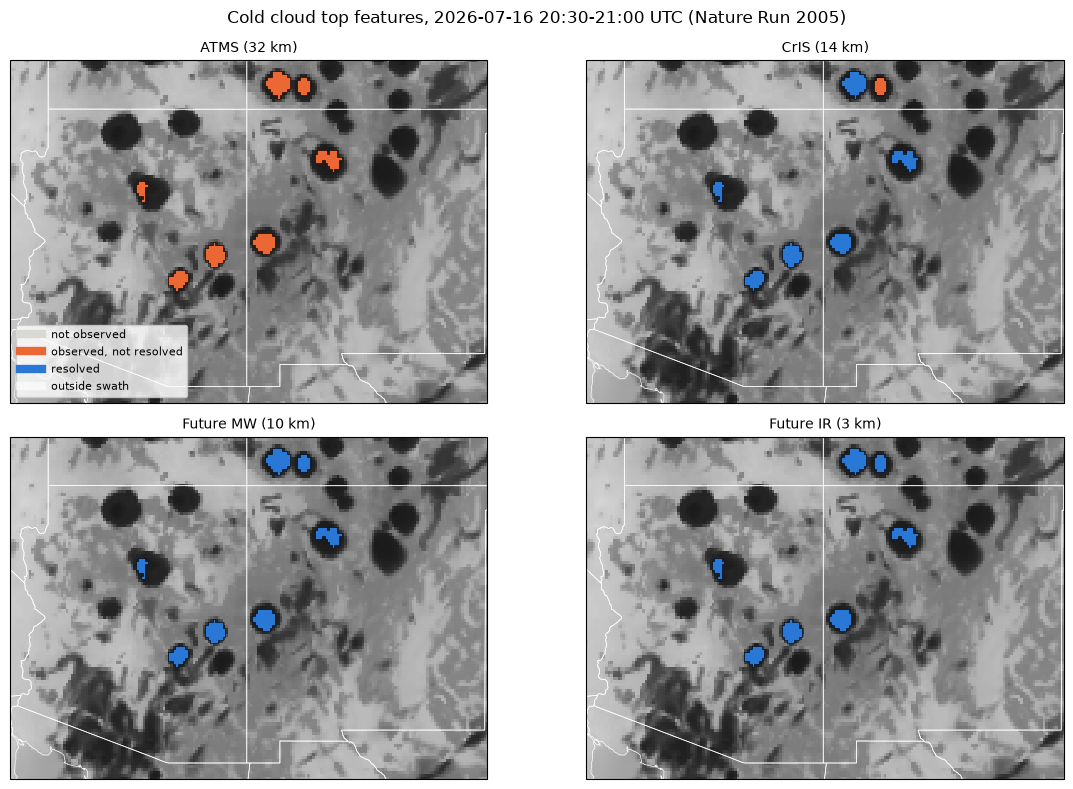

In [7]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# the frame with the most features whose status (not observed, observed, or resolved) differs between the sensors
status = results.observed.astype(int) + results.resolved.astype(int)
example = (
    (status.groupby([results.frame, results.feature]).nunique() > 1)
    .groupby("frame")
    .sum()
    .idxmax()
)
example_time = start + example * frame_duration
STATUS = {
    "not observed": "#d9d8d3",
    "observed, not resolved": "#eb6834",
    "resolved": "#2a78d6",
}

fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), subplot_kw={"projection": ccrs.PlateCarree()}
)
for ax, sensor in zip(axes.ravel(), sensors.index):
    background = nature["lwtup"].isel(time=example)
    ax.pcolormesh(
        background.lon,
        background.lat,
        background,
        cmap="Greys_r",
        vmin=100,
        vmax=450,
        shading="auto",
        transform=ccrs.PlateCarree(),
    )
    members = results[(results.sensor == sensor) & (results.frame == example)]
    status = np.where(
        members.resolved,
        "resolved",
        np.where(members.observed, "observed, not resolved", "not observed"),
    )
    for label, color in STATUS.items():
        selected = features.loc[members.feature[status == label]]
        if len(selected):
            selected.plot(
                ax=ax,
                facecolor=color,
                edgecolor="black",
                linewidth=0.4,
                transform=ccrs.PlateCarree(),
            )
    # fade the part of the study region outside the swath
    swath = swaths.get((example, sensors.loc[sensor, "swath"]))
    outside = domain if swath is None else domain.difference(swath)
    ax.add_geometries(
        [outside],
        crs=ccrs.PlateCarree(),
        facecolor="white",
        edgecolor="none",
        alpha=0.6,
    )
    ax.add_feature(cfeature.STATES, edgecolor="white", linewidth=0.5)
    ax.set_extent(
        [domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]]
    )
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
for label, color in STATUS.items():
    axes[0, 0].plot([], [], color=color, lw=6, label=label)
axes[0, 0].plot([], [], color="#ffffff", lw=6, alpha=0.6, label="outside swath")
axes[0, 0].legend(loc="lower left", fontsize=8, frameon=True)
fig.suptitle(
    f"Cold cloud top features, {example_time:%Y-%m-%d %H:%M}-{example_time + frame_duration:%H:%M} UTC (Nature Run {nature_start:%Y})"
)
fig.tight_layout()
plt.show()

The animation steps through every frame of the two days, with each sensor's features colored as in the figure (drawn over the faded part of the study region outside the swaths of each frame, so that the features not observed remain visible), and a running count of the features each sensor has resolved. The timeline below it gives the number of features in each frame (gray) and the frames in which the satellites pass (black ticks), in local solar time at the center of the study region. (Dark areas that are not features are cloud tops slightly warmer than the threshold or smaller than the minimum size.) It is saved as a GIF in the `data` directory (it is not embedded here, for its size).

In [8]:
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from PIL import Image as PILImage

ANIMATION_FILE = DATA_DIR / "monsoon_feature_status.gif"
FPS = 6  # frames of the nature run per second of the animation
DPI = 80  # pixels per inch of the animation
INK, GRAY_EDGE = "#0b0b0b", "#8a8984"


def save_gif(fig, update, n_frames, path, fps, colors):
    """Saves an animation as a GIF with one layout and one palette (a ramp of grays and the given colors) for all
    frames, without dithering, which keeps the colors of the features exact and compresses far better than a palette
    per frame.
    """
    grays = [(v, v, v) for v in np.linspace(0, 255, 96).round().astype(int)]
    rgb = grays + [
        tuple(int(color[i : i + 2], 16) for i in (1, 3, 5)) for color in colors
    ]
    palette = PILImage.new("P", (1, 1))
    palette.putpalette(
        [v for color in rgb for v in color] + [255] * 3 * (256 - len(rgb))
    )
    fig.set_dpi(DPI)
    # lay the figure out once and keep it: a layout recomputed for each frame (as its titles change) moves the
    # panels by a pixel or so from frame to frame
    update(0)
    fig.canvas.draw()
    fig.set_layout_engine("none")
    frames = []
    for k in range(n_frames):
        update(k)
        fig.canvas.draw()
        image = PILImage.fromarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])
        frames.append(image.quantize(palette=palette, dither=PILImage.Dither.NONE))
    frames[0].save(
        path,
        save_all=True,
        append_images=frames[1:],
        duration=round(1000 / fps),
        loop=0,
        optimize=True,
    )


# local mean solar time at the center of the study region
SOLAR_OFFSET = timedelta(hours=(domain.bounds[0] + domain.bounds[2]) / 2 / 15)

frame_starts = [start + k * frame_duration for k in range(n_frames)]
local_starts = [(t + SOLAR_OFFSET).replace(tzinfo=None) for t in frame_starts]
features_per_frame = (
    features.groupby("frame").size().reindex(range(n_frames), fill_value=0)
)
pass_frames = sorted({frame for frame, _ in swaths.index})
# the status of each feature for each sensor
results["status"] = np.where(
    results.resolved,
    "resolved",
    np.where(results.observed, "observed, not resolved", "not observed"),
)

fig = plt.figure(figsize=(11, 8.4), layout="constrained")
grid = fig.add_gridspec(3, 2, height_ratios=[1, 1, 0.42])
map_axes = [
    fig.add_subplot(grid[row, column], projection=ccrs.PlateCarree())
    for row in range(2)
    for column in range(2)
]
timeline = fig.add_subplot(grid[2, :])
meshes, tallies = {}, {}
dynamic = []  # the artists of the current frame
for ax, sensor in zip(map_axes, sensors.index):
    meshes[sensor] = ax.pcolormesh(
        nature.lon,
        nature.lat,
        nature["lwtup"].isel(time=0),
        cmap="Greys_r",
        vmin=100,
        vmax=450,
        shading="auto",
        transform=ccrs.PlateCarree(),
    )
    ax.add_feature(cfeature.STATES, edgecolor="white", linewidth=0.5)
    ax.set_extent(
        [domain.bounds[0], domain.bounds[2], domain.bounds[1], domain.bounds[3]]
    )
    ax.set_title(f"{sensor} ({sensors.loc[sensor, 'horizontal_km']} km)", fontsize=10)
    tallies[sensor] = ax.text(
        0.01,
        0.98,
        "",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        color=INK,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.85, "pad": 2},
    )

timeline.bar(
    local_starts,
    features_per_frame,
    width=frame_duration * 0.9,
    align="edge",
    color="#d9d8d3",
    label="features in the frame",
)
timeline.vlines(
    [local_starts[frame] + frame_duration / 2 for frame in pass_frames],
    0,
    -0.12 * features_per_frame.max(),
    color=INK,
    lw=1.5,
    label="satellite passes",
)
cursor = timeline.axvline(local_starts[0], color=STATUS["resolved"], lw=2)
timeline.set(
    xlim=(local_starts[0], local_starts[-1] + frame_duration),
    ylabel="Features",
    xlabel="Local solar time",
)
timeline.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 6)))
timeline.xaxis.set_major_formatter(mdates.DateFormatter("%d %b\n%H:%M"))
timeline.spines[["top", "right"]].set_visible(False)
# one legend, above the timeline, so that it covers no features
handles = [
    Patch(facecolor=color, edgecolor="black", linewidth=0.4, label=label)
    for label, color in STATUS.items()
]
handles.append(
    Patch(facecolor="#f4f4f2", edgecolor=GRAY_EDGE, label="outside swath (faded)")
)
handles += timeline.get_legend_handles_labels()[0]
timeline.legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncols=len(handles),
    fontsize=8,
    frameon=False,
)
title = fig.suptitle("", fontsize=12)


def update(k):
    """Draws frame k of the nature run, with each sensor's features and swaths."""
    while dynamic:
        dynamic.pop().remove()
    for ax, sensor in zip(map_axes, sensors.index):
        meshes[sensor].set_array(nature["lwtup"].isel(time=k).values)
        # fade the part of the study region outside the swath, beneath the features
        swath = swaths.get((k, sensors.loc[sensor, "swath"]))
        outside = domain if swath is None else domain.difference(swath)
        dynamic.append(
            ax.add_geometries(
                [outside],
                crs=ccrs.PlateCarree(),
                facecolor="white",
                edgecolor="none",
                alpha=0.6,
                zorder=2,
            )
        )
        members = results[(results.sensor == sensor) & (results.frame == k)]
        for label, color in STATUS.items():
            selected = features.geometry.loc[members.feature[members.status == label]]
            if len(selected):
                dynamic.append(
                    ax.add_geometries(
                        selected,
                        crs=ccrs.PlateCarree(),
                        facecolor=color,
                        edgecolor="black",
                        linewidth=0.4,
                        zorder=3,
                    )
                )
        so_far = results[(results.sensor == sensor) & (results.frame <= k)]
        tallies[sensor].set_text(
            f"resolved so far: {so_far.resolved.sum()} of {len(so_far)} features"
        )
    cursor.set_xdata([local_starts[k] + frame_duration / 2] * 2)
    title.set_text(
        f"North American Monsoon convection, {local_starts[k]:%d %B %H:%M}-"
        f"{local_starts[k] + frame_duration:%H:%M} local solar time"
    )


save_gif(fig, update, n_frames, ANIMATION_FILE, FPS, colors=[*STATUS.values(), INK])
plt.close(fig)
print(
    f"{ANIMATION_FILE}: {n_frames} frames, {ANIMATION_FILE.stat().st_size / 1e6:.1f} MB"
)

data\monsoon_feature_status.gif: 96 frames, 8.1 MB


### Simulate What Each Sensor Sees

The figures above color the features by their status; an image shows what lies behind it. As in the [cold pool OSSE](RunOSSEColdPools.ipynb), this section simulates the image of the cold cloud tops that each sensor records on the pass in the frame of the figure above. TAT-C's `collect_ground_pixels` gives the center of each sample of a sensor at each scan (scans separated by the time in which the ground track advances by the sample spacing), and `compute_sample_sizes` the size of each sample's footprint along and across track. Each sample's value is the upwelling longwave flux averaged over its footprint, weighted by a Gaussian whose full width at half maximum is the footprint's size, drawn as a tile of the sample spacing on the nature run's grid. Each feature is outlined by its status for the sensor, in the colors of the figure above, and each panel counts the features the sensor resolves.

The nature run's grid (0.0625 degrees, about 7 km) is coarser than the future infrared sounder's footprint, so the image of that sensor shows only what the nature run does: the images show how much detail the heritage sensors and the future microwave sounder lose, not what a 3 km sensor would gain over the nature run.

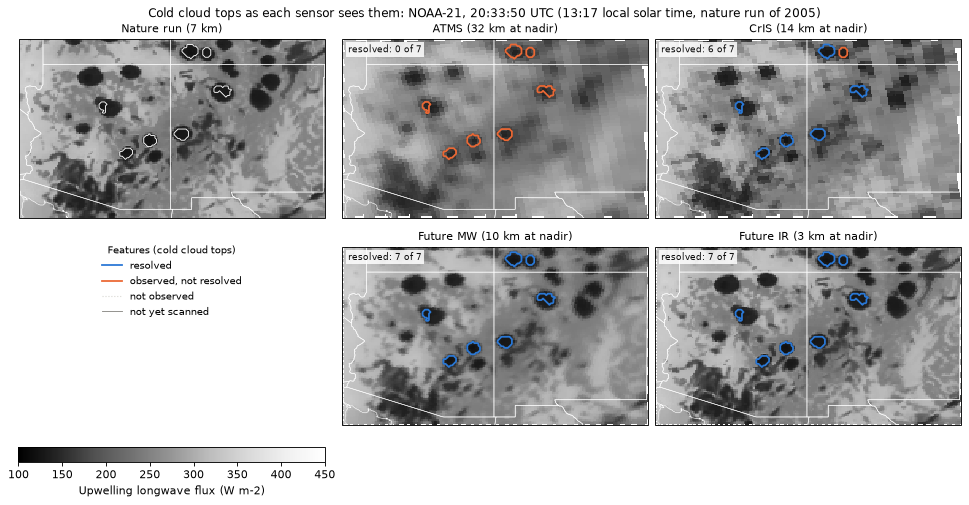

data\monsoon_sensor_views.gif: 68 frames, 0.2 MB; ATMS resolved: 0 of 7, CrIS resolved: 6 of 7, Future MW resolved: 7 of 7, Future IR resolved: 7 of 7


In [9]:
from matplotlib.lines import Line2D

from tatc.analysis import collect_ground_pixels
from tatc.utils import compute_ground_inertial_velocity

VIEW_FILE = DATA_DIR / "monsoon_sensor_views.gif"
VIEW_FRAME_SECONDS = 3  # s of the pass per frame of the animation
VIEW_FPS = 10  # frames per second of the animation
VIEW_HOLD_FRAMES = 20  # frames that hold the complete images at the end
TILE = 1.1  # the size of a sample's tile, relative to the sample spacing
KM_PER_DEG = np.pi * EARTH_MEAN_RADIUS / 180 / 1e3  # km per degree of latitude
OUTLINES = {  # the outline of a feature by its status: color, width, style
    "resolved": (STATUS["resolved"], 1.6, "solid"),
    "observed, not resolved": (STATUS["observed, not resolved"], 1.6, "solid"),
    "not observed": (STATUS["not observed"], 1.0, "dotted"),
    "not yet scanned": ("#8a8984", 0.8, "solid"),
}

# the pass in the frame of the figure: the satellite with the most footprints in the study region in the frame
frame_tracks = tracks[tracks.frame == example]
view_name = frame_tracks.satellite.value_counts().idxmax()
view_satellite = next(s for s in satellites if s.name == view_name)
view_times = frame_tracks[frame_tracks.satellite == view_name].time
lon, lat = nature.lon.values, nature.lat.values
grid_lon, grid_lat = np.meshgrid(lon, lat)
field = nature["lwtup"].isel(time=example).values
# the features of the frame on the grid (by their index), and their status for each sensor
frame_features = features[features.frame == example]
feature_grid = np.full(field.shape, -1)
for index, polygon in frame_features.geometry.items():
    feature_grid[shapely.contains_xy(polygon, grid_lon, grid_lat)] = index
view_status = {
    sensor: results[(results.sensor == sensor) & (results.frame == example)].set_index(
        "feature"
    )["status"]
    for sensor in sensors.index
}


def collect_view_samples(sensor):
    """The samples of a sensor on the pass over the study region: their time, position, footprint and spacing (km,
    along and across track), cross-track direction (east and north), and value (the flux averaged over the
    footprint)."""
    row = sensors.loc[sensor]
    sensor_satellite = view_satellite.model_copy(
        update={"instruments": [sensor_instrument(sensor)]}
    )
    speed = (
        compute_ground_inertial_velocity(view_satellite.orbit.get_mean_altitude()) / 1e3
    )
    step = timedelta(seconds=row.sampling_km / speed)
    first = view_times.min() - timedelta(seconds=TIME_STEP)
    last = view_times.max() + timedelta(seconds=TIME_STEP)
    times = [first + k * step for k in range(int((last - first) / step) + 1)]
    pixels = collect_ground_pixels(sensor_satellite, times, mask=domain)
    pixels = compute_sample_sizes(
        pixels[pixels.valid_obs].reset_index(drop=True), sensor_satellite
    )
    s = pd.DataFrame(
        {"time": pixels.time, "lon": pixels.geometry.x, "lat": pixels.geometry.y}
    )
    for column in ("sample_along", "sample_cross", "spacing_along", "spacing_cross"):
        s[column] = pixels[column].values / 1e3
    # the cross-track direction (unit vector, km east and north): from neighboring samples of a scan
    east = s.lon * KM_PER_DEG * np.cos(np.radians(s.lat))
    north = s.lat * KM_PER_DEG
    direction = np.full((len(s), 2), np.nan)
    for _, scan in s.groupby("time"):
        if len(scan) > 1:
            direction[scan.index] = np.column_stack(
                [np.gradient(east[scan.index]), np.gradient(north[scan.index])]
            )
    direction /= np.linalg.norm(direction, axis=1, keepdims=True)
    s["cross_east"], s["cross_north"] = direction[:, 0], direction[:, 1]
    return s[np.isfinite(s.cross_east)].reset_index(drop=True)


def footprint_offsets(sample, reach):
    """The grid cells within a distance (km) of a sample, and their offsets across and along track (km)."""
    rows = np.nonzero(np.abs(lat - sample.lat) * KM_PER_DEG <= reach)[0]
    columns = np.nonzero(
        np.abs(lon - sample.lon) * KM_PER_DEG * np.cos(np.radians(sample.lat)) <= reach
    )[0]
    d_east = (
        (lon[columns][None, :] - sample.lon)
        * KM_PER_DEG
        * np.cos(np.radians(sample.lat))
    )
    d_north = (lat[rows][:, None] - sample.lat) * KM_PER_DEG
    cross = d_east * sample.cross_east + d_north * sample.cross_north
    along = -d_east * sample.cross_north + d_north * sample.cross_east
    return rows, columns, cross, along


def view_image(s):
    """A sensor's image on the nature run's grid: each sample's value (the flux averaged over its footprint, with
    Gaussian weights) in the cells of its tile (of the sample spacing), the nearest sample's where tiles overlap, with
    the time of the sample (s from the start of the scenario), and NaN where no tile covers a cell.
    """
    value, seconds = np.full(field.shape, np.nan), np.full(field.shape, np.nan)
    distance = np.full(field.shape, np.inf)
    for sample in s.itertuples():
        rows, columns, cross, along = footprint_offsets(
            sample, 1.2 * max(sample.sample_along, sample.sample_cross)
        )
        weight = np.exp(
            -4
            * np.log(2)
            * ((cross / sample.sample_cross) ** 2 + (along / sample.sample_along) ** 2)
        )
        mean = np.sum(weight * field[np.ix_(rows, columns)]) / np.sum(weight)
        rows, columns, cross, along = footprint_offsets(
            sample, TILE * max(sample.spacing_along, sample.spacing_cross)
        )
        # tiles slightly larger than the spacing, so that no cell between them is missed (the nearest sample
        # takes a cell where they overlap)
        inside = (np.abs(cross) <= TILE * sample.spacing_cross / 2) & (
            np.abs(along) <= TILE * sample.spacing_along / 2
        )
        r = np.hypot(cross, along)
        nearer = inside & (r < distance[np.ix_(rows, columns)])
        i, j = np.nonzero(nearer)
        value[rows[i], columns[j]] = mean
        seconds[rows[i], columns[j]] = (sample.time - start).total_seconds()
        distance[rows[i], columns[j]] = r[i, j]
    return value, seconds


view_samples = {sensor: collect_view_samples(sensor) for sensor in sensors.index}
view_images = {sensor: view_image(s) for sensor, s in view_samples.items()}
# the time (s from the start) at which each sensor has scanned all of each feature of the frame that it scans
view_scanned = {}
for sensor in sensors.index:
    seconds = view_images[sensor][1]
    view_scanned[sensor] = pd.Series(
        {
            index: (
                np.nanmax(seconds[feature_grid == index])
                if np.isfinite(seconds[feature_grid == index]).any()
                else np.inf
            )
            for index in frame_features.index
        }
    )


def draw_feature_outlines(ax, groups):
    """Outlines of the features of each group (a status and the indices of its features); returns the contours."""
    contours = []
    for status, indices in groups.items():
        if len(indices):
            color, width, style = OUTLINES[status]
            contours.append(
                ax.contour(
                    lon,
                    lat,
                    np.isin(feature_grid, indices),
                    levels=[0.5],
                    colors=color,
                    linewidths=width,
                    linestyles=style,
                    transform=ccrs.PlateCarree(),
                )
            )
    return contours


def draw_sensor_views(fig):
    """Panels of the nature run and of each sensor's image of the study region, with the features outlined by
    their status; returns the image, outlines, and count of resolved features of each sensor.
    """
    grid = fig.add_gridspec(2, 3)
    panels = {
        "Nature run": grid[0, 0],
        "ATMS": grid[0, 1],
        "CrIS": grid[0, 2],
        "Future MW": grid[1, 1],
        "Future IR": grid[1, 2],
    }
    extent = [lon[0], lon[-1], lat[0], lat[-1]]
    images, outlines, counts = {}, {}, {}
    for name, cell in panels.items():
        ax = fig.add_subplot(cell, projection=ccrs.PlateCarree())
        data = field if name == "Nature run" else view_images[name][0]
        images[name] = ax.imshow(
            data,
            cmap="Greys_r",
            vmin=100,
            vmax=450,
            origin="lower",
            extent=extent,
            interpolation="nearest",
            transform=ccrs.PlateCarree(),
        )
        ax.add_feature(cfeature.STATES, edgecolor="white", linewidth=0.5)
        ax.set_extent(extent, crs=ccrs.PlateCarree())
        if name == "Nature run":
            ax.set_title("Nature run (7 km)", fontsize=10)
            ax.contour(
                lon,
                lat,
                feature_grid >= 0,
                levels=[0.5],
                colors="#ffffff",
                linewidths=0.8,
                transform=ccrs.PlateCarree(),
            )
        else:
            ax.set_title(
                f"{name} ({sensors.loc[name, 'horizontal_km']} km at nadir)",
                fontsize=10,
            )
            status = view_status[name]
            outlines[name] = draw_feature_outlines(
                ax, {label: status.index[status == label] for label in STATUS}
            )
            counts[name] = ax.text(
                0.02,
                0.97,
                "",
                transform=ax.transAxes,
                va="top",
                fontsize=8,
                color=INK,
                zorder=5,
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.85,
                    "pad": 2,
                },
            )
    # the legend and color bar in the panel below the nature run
    info = fig.add_subplot(grid[1, 0])
    info.axis("off")
    info.legend(
        handles=[
            Line2D([], [], color=color, lw=width, ls=style, label=label)
            for label, (color, width, style) in OUTLINES.items()
        ],
        loc="upper center",
        fontsize=9,
        frameon=False,
        title="Features (cold cloud tops)",
        title_fontsize=9,
    )
    fig.colorbar(
        images["Nature run"],
        ax=info,
        orientation="horizontal",
        location="bottom",
        fraction=0.12,
        label="Upwelling longwave flux (W m-2)",
    )
    return images, outlines, counts


def count_resolved(sensor, indices):
    """The count of the features that a sensor resolves among some (by index), of those of the frame."""
    resolved = (
        (view_status[sensor].loc[indices] == "resolved").sum() if len(indices) else 0
    )
    return f"resolved: {resolved} of {len(frame_features)}"


view_frame_times = pd.date_range(
    min(s.time.min() for s in view_samples.values()),
    max(s.time.max() for s in view_samples.values())
    + pd.Timedelta(seconds=VIEW_FRAME_SECONDS),
    freq=f"{VIEW_FRAME_SECONDS}s",
)
fig = plt.figure(figsize=(12, 6.2), layout="constrained")
view_artists = draw_sensor_views(fig)
view_title = fig.suptitle("", fontsize=11)


def update_views(k):
    """Shows the samples up to the time of animation frame k (the complete images after the last time), with the
    features outlined by their status once they are scanned."""
    images, outlines, counts = view_artists
    t = view_frame_times[min(k, len(view_frame_times) - 1)]
    elapsed = (t - start).total_seconds()
    for sensor in sensors.index:
        value, seconds = view_images[sensor]
        images[sensor].set_data(np.where(seconds <= elapsed, value, np.nan))
        while outlines[sensor]:
            outlines[sensor].pop().remove()
        status = view_status[sensor]
        done = view_scanned[sensor].loc[status.index] <= elapsed
        if k >= len(view_frame_times):
            done = view_scanned[sensor].loc[status.index] < np.inf
        groups = {label: status.index[(status == label) & done] for label in STATUS}
        groups["not yet scanned"] = status.index[~done & (status != "not observed")]
        groups["not observed"] = status.index[status == "not observed"]
        outlines[sensor] = draw_feature_outlines(images[sensor].axes, groups)
        counts[sensor].set_text(count_resolved(sensor, status.index[done]))
    local = t + timedelta(hours=(domain.bounds[0] + domain.bounds[2]) / 2 / 15)
    view_title.set_text(
        f"Cold cloud tops as each sensor sees them: {view_name}, {t:%H:%M:%S} UTC "
        f"({local:%H:%M} local solar time, nature run of {nature_start:%Y})"
    )


# one layout and palette for all frames (see `save_gif`): the grays of the images and the colors of the outlines
save_gif(
    fig,
    update_views,
    len(view_frame_times) + VIEW_HOLD_FRAMES,
    VIEW_FILE,
    VIEW_FPS,
    colors=[*STATUS.values(), OUTLINES["not yet scanned"][0], INK],
)
update_views(len(view_frame_times))  # the complete images, shown below
plt.show()
print(
    f"{VIEW_FILE}: {len(view_frame_times) + VIEW_HOLD_FRAMES} frames, "
    f"{VIEW_FILE.stat().st_size / 1e6:.1f} MB; "
    + ", ".join(
        f"{sensor} {count_resolved(sensor, view_status[sensor].index)}"
        for sensor in sensors.index
    )
)

On NOAA-21's pass in this frame (about 13:15 local solar time), every sensor observes all seven features. ATMS's footprints blur the cold cloud tops into broad gray patches whose cores are no longer cold, and it resolves none of the features; CrIS keeps the shapes of most of them and resolves six; and both future sensors resolve all seven. The animation of the pass is saved as a GIF in the `data` directory (it is not embedded here, for its size), and shows each sensor's image built scan by scan, with each feature outlined in gray until the sensor has scanned all of it, then by its status.

## Generate Statistics

The table gives, for each sensor, the share of all features that are observed and resolved, the share of the total feature area and of the total convective precipitation that lies in resolved features, and the median resolution element at the observed features. The shares of area and precipitation count the whole of each resolved feature, even if only part of it is viewed.

In [10]:
total = {
    "features": len(features),
    "area": features.area_km2.sum(),
    "precipitation": features.tot_preccon.sum(),
}
summary = (
    results.groupby("sensor")
    .apply(
        lambda r: pd.Series(
            {
                "observed (% of features)": 100 * r.observed.mean(),
                "resolved (% of features)": 100 * r.resolved.mean(),
                "resolved (% of area)": 100
                * r.area_km2[r.resolved].sum()
                / total["area"],
                "resolved (% of precipitation)": 100
                * r.tot_preccon[r.resolved].sum()
                / total["precipitation"],
                "median resolution element of observed (km)": r.element_km[
                    r.observed
                ].median(),
            }
        ),
        include_groups=False,
    )
    .loc[sensors.index]
)
summary.round(1)

,observed (% of features),resolved (% of features),resolved (% of area),resolved (% of precipitation),median resolution element of observed (km)
sensor,,,,,
ATMS,9.8,0.4,0.8,1.3,50.5
CrIS,7.7,4.2,4.2,9.4,20.7
Future MW,9.8,7.4,7.2,14.5,15.8
Future IR,7.7,7.7,6.1,13.4,4.2


Over the two days, the study region has 285 features at least 28 km in size (the median is 47 km, and three quarters are smaller than 66 km). The sounders observe 8 to 10% of them (22 in the CrIS swath and 28 in the wider ATMS swath), because the two satellites are in the same orbit plane and cross the region within about an hour (near 13:30 local time) on their afternoon passes and again about 12 hours later (near 01:30), whereas the features concentrate in the afternoon and evening (see the solar hour below); finer resolution does not change this, because the swaths are the same. Only a few observed features straddle a swath edge (4 in the ATMS swath and none in the CrIS swath, at their best look), so counting the viewed part rather than the centroid changes little here: requiring the centroid to be in the swath would observe one fewer feature in the ATMS swath, and as many in the CrIS swath.

Among the features observed, resolution matters a great deal: with a criterion of two resolution elements, ATMS resolves almost none of them (1 of 28), because the median resolution element at the observed features (50 km, larger than its 32 km nadir footprint because features are observed away from nadir) exceeds the 47 km median feature. CrIS resolves about half (12 of 22), with a median element of 21 km set by its sample spacing rather than its footprint. A future microwave sounder resolves three quarters (21 of 28), and a future infrared sounder, sampling in proportion to its 3 km footprint, all of them (22 of 22), with a median of about 10 elements across each.

Because the larger features (which are resolved first) are also the wetter ones, the resolved share of convective precipitation is greater than the resolved share of features (9% for CrIS, 15% for a future microwave sounder, and 13% for a future infrared sounder). The future infrared sounder resolves a slightly smaller share of precipitation than the future microwave sounder because the CrIS swath is narrower than the ATMS swath, so it observes fewer features (22 vs. 28): once the resolution is fine enough, observability is limited by the swath. With a single two-day realization, differences of a point or two between the future sensors are within sampling noise.

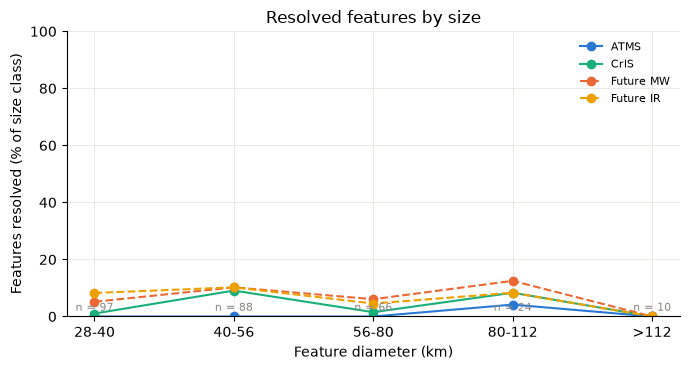

size_class,28-40,40-56,56-80,80-112,>112
sensor,,,,,
ATMS,0.0,0.0,0.0,4.2,0.0
CrIS,1.0,9.1,1.5,8.3,0.0
Future MW,5.2,10.2,6.1,12.5,0.0
Future IR,8.2,10.2,4.5,8.3,0.0


In [11]:
BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = (
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#8a8984",
    "#0b0b0b",
)
SENSOR_COLORS = {"ATMS": BLUE, "Future MW": ORANGE, "CrIS": AQUA, "Future IR": YELLOW}
SENSOR_STYLES = {"ATMS": "-", "Future MW": "--", "CrIS": "-", "Future IR": "--"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
    }
)

edges = np.array([EFFECTIVE_RESOLUTION_KM, 40, 56, 80, 112, np.inf])
labels = [f"{EFFECTIVE_RESOLUTION_KM}-40", "40-56", "56-80", "80-112", ">112"]
results["size_class"] = pd.cut(results.diameter_km, edges, labels=labels, right=False)
by_size = (
    results.groupby(["sensor", "size_class"], observed=False)
    .resolved.mean()
    .unstack()
    .loc[sensors.index]
    * 100
)
counts = results[results.sensor == "ATMS"].groupby("size_class", observed=False).size()

fig, ax = plt.subplots(figsize=(7, 3.8))
for sensor in sensors.index:
    ax.plot(
        labels,
        by_size.loc[sensor],
        marker="o",
        color=SENSOR_COLORS[sensor],
        ls=SENSOR_STYLES[sensor],
        label=sensor,
    )
ax.set(
    xlabel="Feature diameter (km)",
    ylabel="Features resolved (% of size class)",
    title="Resolved features by size",
    ylim=(0, 100),
)
ax.legend(frameon=False, fontsize=8)
for x, n in zip(labels, counts):
    ax.annotate(f"n = {n}", (x, 2), ha="center", fontsize=8, color=GRAY)
fig.tight_layout()
plt.show()
by_size.round(1)

Resolution matters most for the smaller features. The shares are of all features in each size class, so they also reflect how many of them are observed (none of the 10 features larger than 112 km happens to be observed), and those of a future infrared sounder, which resolves every feature it observes, are its observed shares. The sensors differ most for the features smaller than 56 km: of those of 28 to 40 km, a future infrared sounder resolves 8%, a future microwave sounder 5%, CrIS 1%, and ATMS none, and of those of 40 to 56 km, either future sensor 10%, CrIS 9%, and ATMS none. ATMS resolves only features of 80 to 112 km (4% of them).

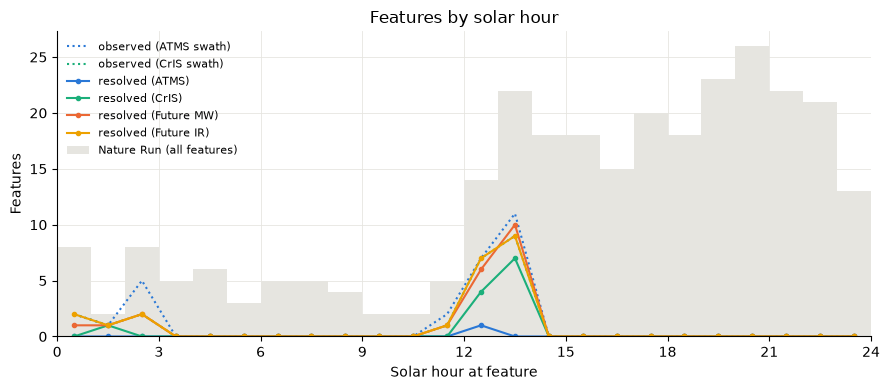

In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 25, 1)
nature_hist, _ = np.histogram(features.solar_hour, bins)
ax.bar(
    bins[:-1] + 0.5,
    nature_hist,
    width=1,
    color="#e6e5e0",
    label="Nature Run (all features)",
)
for swath, style, color in [("ATMS", ":", BLUE), ("CrIS", ":", AQUA)]:
    r = results[results.sensor == swath]
    hist, _ = np.histogram(r.solar_hour[r.observed], bins)
    ax.plot(
        bins[:-1] + 0.5, hist, ls=":", color=color, label=f"observed ({swath} swath)"
    )
for sensor in sensors.index:
    r = results[results.sensor == sensor]
    hist, _ = np.histogram(r.solar_hour[r.resolved], bins)
    ax.plot(
        bins[:-1] + 0.5,
        hist,
        ls="-",
        marker="o",
        ms=3,
        color=SENSOR_COLORS[sensor],
        label=f"resolved ({sensor})",
    )
ax.set(
    xlabel="Solar hour at feature",
    ylabel="Features",
    title="Features by solar hour",
    xlim=(0, 24),
)
ax.set_xticks(range(0, 25, 3))
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

The solar hour of the features shows when the sampling gap arises. Features are most frequent in the late afternoon and evening (about 17 to 21 solar hours), after the satellites' afternoon pass (near 13:30), which samples the developing convection, and well before their next pass (near 01:30), which samples the decaying convection. A constellation with a different distribution of local times (for example, satellites in other orbit planes) would observe more of the features, independently of resolution, as the constellation trade below shows.

In [13]:
# sensitivity to the resolution criterion: the share of features resolved if their viewed part must span at least N
# resolution elements, of either size
sensitivity = pd.DataFrame(
    {
        (axis, f"N = {n}"): results.groupby("sensor")[f"elements ({axis})"].apply(
            lambda r: 100 * (r >= n).mean()
        )
        for axis in AXES
        for n in (1, 2, 3)
    }
).loc[sensors.index]
sensitivity.round(1)

equivalent             cross-track             quadrature        \
               N = 1 N = 2 N = 3       N = 1 N = 2 N = 3      N = 1 N = 2   
sensor                                                                      
ATMS             4.2   0.4   0.0         3.5   0.4   0.0        3.2   0.4   
CrIS             7.4   4.2   1.1         6.7   3.5   1.1        6.0   3.2   
Future MW        9.1   7.4   5.3         8.8   6.3   4.2        9.1   6.7   
Future IR        7.7   7.7   7.7         7.7   7.7   7.7        7.7   7.7   

                 
          N = 3  
sensor           
ATMS        0.0  
CrIS        0.4  
Future MW   3.9  
Future IR   7.7

Each sensor resolves fewer features with a stricter criterion: more resolution elements across a feature, or the cross-track size of the element. A future infrared sounder is insensitive to either (it resolves every feature it observes, even with three cross-track elements), whereas the resolved share of a future microwave sounder falls from 9% to 5% as the criterion tightens from one to three equivalent elements, and to 4% with three cross-track elements. With a lenient criterion of one element, a future microwave sounder resolves more features than a future infrared sounder, because its wider swath observes more. The cross-track measure lowers the shares by at most about 1 percentage point, much less than the number of elements does, because most observed features are viewed at moderate zenith angles (a median of 35 to 44 degrees), where the cross-track size exceeds the equivalent diameter by only 10 to 18%. Adding the footprint and the spacing in quadrature lowers the share resolved by CrIS most, from 4.2% to 3.2% with two elements, because its views are spaced by little more than their size, and that of a future microwave sounder from 7.4% to 6.7%, whereas a future infrared sounder still resolves every feature it observes and ATMS the same 0.4%; the ranking of the sensors does not change.

## Trade the Constellation Design

An OSSE is most useful for comparing designs that do not exist yet. The analysis above finds that the current sounders observe only 8 to 10% of the features, because both satellites share one orbit plane, and that finer resolution helps only with the features that are observed. This section trades the two: how many satellites, in how many orbit planes, carrying heritage or future sensors.

The designs are declared as a design space (`tatc.tradespace.DesignSpace`): the number of orbit planes `P` (a repetition of planes, `Repeat`) and the number of satellites in each plane, for at most six satellites, which gives 14 designs. Each design places satellites in sun-synchronous orbits at 830 km (the altitude at which the nominal resolutions of the sensors apply), in planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30 (a value `Derived` from the index of the plane), so that `P` planes observe at `2P` evenly spaced local times. The satellites of a plane are evenly spaced in it, and each carries both swaths (ATMS and CrIS). The designs include the two strategies of all satellites in one plane, like the current constellation, and one satellite per plane, and designs in between, such as 6 satellites in 2 planes (3 per plane), which shows how much of the benefit of separate planes a single additional plane gives.

Which passes cross the study region depends on the phase of the satellites in their planes, which is not a design choice but an uncertain parameter (`Uncertain`). A trade study (`tatc.tradespace.Study`) builds and evaluates each design in `N_DRAWS` replicates, each with random phases, and the results are averaged. The replicates use common random numbers: the phase of a plane (the first plane, the second plane, and so on) is the same in the same replicate of every design, so that differences between designs are not differences between their draws.

Designs share satellites: in the same replicate, the first satellite of the first plane is the same in every design, and so are others (such as the satellites of the planes of designs with the same number of planes). A cache of the looks of each satellite (`tatc.tradespace.SatelliteCache`), keyed by its orbit and instruments rather than its name, computes them once for the designs of a replicate: 32 satellites rather than 57. The replicates are evaluated in parallel, each by its own worker process (`n_jobs`).

Two days are too few to rank designs, so the trade uses two weeks of the Nature Run (`TRADE_DURATION`), downloaded once (about 120 MB, a few minutes). Evaluating the designs takes about a minute with six processors.

In [14]:
from datetime import time as time_of_day

from tatc.schemas import SunSynchronousOrbit
from tatc.tradespace import (
    Derived,
    DesignSpace,
    Integer,
    Repeat,
    SatelliteCache,
    Study,
    Uncertain,
)

TRADE_DURATION = timedelta(days=14)
N_DRAWS = 6  # replicates of each design: random phases of the satellites in their planes

# the design space: P planes whose ascending equator crossing times are spread evenly over 12 hours from 13:30, each
# with the same number of satellites at a random phase, for at most 6 satellites
space = DesignSpace(
    per_plane=Integer(1, 6),
    planes=Repeat(
        DesignSpace(
            crossing=Derived(lambda d: (13.5 + 12 * d.index / d.planes.count) % 24),
            phase=Uncertain.uniform(0, 360),
        ),
        count=Integer(1, 6),
    ),
    constraints=[lambda d: d.planes.count * d.per_plane <= 6],
)


def build(design):
    """The satellites of a design: in sun-synchronous orbits at 830 km, evenly spaced in each plane from its phase."""
    members = []
    for p, plane in enumerate(design.planes):
        crossing = time_of_day(int(plane.crossing), round(60 * (plane.crossing % 1)) % 60)
        for s in range(design.per_plane):
            orbit = SunSynchronousOrbit(
                altitude=830e3,
                equator_crossing_time=crossing,
                epoch=start,
                true_anomaly=(plane.phase + 360 * s / design.per_plane) % 360,
            )
            members.append(sounder_satellite(f"plane {p + 1} satellite {s + 1}", orbit))
    return members


def evaluate(members, features, cache=None):
    """The share (%) of the features that each sensor observes and resolves, flown on the members, with their looks
    from a cache of the looks of each satellite (in the order of the features and times, as for all members), if any.
    """
    if cache is None:
        looks = collect_looks(members, TRADE_DURATION, features)
    else:
        looks = cache(members).sort_values(["feature", "time"], kind="stable", ignore_index=True)
    return (
        assess(looks, features, members)
        .groupby("sensor")[["observed", "resolved"]]
        .mean()
        .mul(100)
    )


trade_features = find_features(load_nature(TRADE_DURATION))
# the looks of each satellite, cached by its orbit and instruments (not its name): designs of the same replicate
# share satellites, such as the first satellite of the first plane
trade_looks = SatelliteCache(lambda satellite: collect_looks([satellite], TRADE_DURATION, trade_features))
# common random numbers: the phase of a plane is the same in the same replicate of every design; each replicate is
# evaluated by its own worker process, whose cache its designs share
study = Study(
    space,
    build,
    lambda members: evaluate(members, trade_features, trade_looks),
    replicates=N_DRAWS,
    n_jobs=N_DRAWS,
    chunks_per_job=1,
)
trade = study.run()
trade["planes"] = trade["planes.count"]
trade["satellites"] = trade.planes * trade.per_plane
trade["design"] = (
    trade.planes.astype(str) + " plane(s) x " + trade.per_plane.astype(str)
)
# the current constellation over the same two weeks, for reference
current = evaluate(satellites, trade_features).assign(
    satellites=len(satellites), design=f"current ({len(satellites)} in the 13:30 plane)"
)

# features observed (by each swath) and resolved (by each sensor), % of all features, averaged over the replicates
trade_summary = pd.concat([trade, current.reset_index()]).pivot_table(
    index=["satellites", "design"], columns="sensor", values=["observed", "resolved"]
)
trade_summary = pd.concat(
    [
        trade_summary["observed"][["ATMS", "CrIS"]]
        .add_prefix("observed, ")
        .add_suffix(" swath"),
        trade_summary["resolved"][sensors.index].add_prefix("resolved, "),
    ],
    axis=1,
)
print(f"{len(space.enumerate())} designs, {len(trade_features)} features in {TRADE_DURATION.days} days")
trade_summary.round(1)

14 designs, 1590 features in 14 days


sensor                                     observed, ATMS swath  \
satellites design                                                 
1          1 plane(s) x 1                                   4.4   
2          1 plane(s) x 2                                   8.5   
           2 plane(s) x 1                                  10.1   
           current (2 in the 13:30 plane)                   8.2   
3          1 plane(s) x 3                                  12.9   
           3 plane(s) x 1                                  14.1   
4          1 plane(s) x 4                                  14.7   
           2 plane(s) x 2                                  19.6   
           4 plane(s) x 1                                  19.4   
5          1 plane(s) x 5                                  15.4   
           5 plane(s) x 1                                  24.3   
6          1 plane(s) x 6                                  15.8   
           2 plane(s) x 3                                  29.7   
           3 plane(s) x 2                                  28.0   
           6 plane(s) x 1                                  29.2   

sensor                                     observed, CrIS swath  \
satellites design                                                 
1          1 plane(s) x 1                                   3.4   
2          1 plane(s) x 2                                   6.8   
           2 plane(s) x 1                                   7.9   
           current (2 in the 13:30 plane)                   6.7   
3          1 plane(s) x 3                                  10.4   
           3 plane(s) x 1                                  11.3   
4          1 plane(s) x 4                                  12.3   
           2 plane(s) x 2                                  15.7   
           4 plane(s) x 1                                  15.5   
5          1 plane(s) x 5                                  12.9   
           5 plane(s) x 1                                  19.6   
6          1 plane(s) x 6                                  13.1   
           2 plane(s) x 3                                  23.9   
           3 plane(s) x 2                                  22.7   
           6 plane(s) x 1                                  23.8   

sensor                                     resolved, ATMS  resolved, CrIS  \
satellites design                                                           
1          1 plane(s) x 1                             0.4             1.9   
2          1 plane(s) x 2                             0.8             4.1   
           2 plane(s) x 1                             1.1             4.3   
           current (2 in the 13:30 plane)             0.8             3.9   
3          1 plane(s) x 3                             1.2             6.2   
           3 plane(s) x 1                             1.6             6.6   
4          1 plane(s) x 4                             1.5             7.4   
           2 plane(s) x 2                             2.4             9.2   
           4 plane(s) x 1                             2.2             9.0   
5          1 plane(s) x 5                             1.7             8.1   
           5 plane(s) x 1                             2.6            11.5   
6          1 plane(s) x 6                             1.8             8.4   
           2 plane(s) x 3                             3.6            14.2   
           3 plane(s) x 2                             3.5            13.8   
           6 plane(s) x 1                             3.5            14.2   

sensor                                     resolved, Future MW  \
satellites design                                                
1          1 plane(s) x 1                                  3.2   
2          1 plane(s) x 2                                  6.8   
           2 plane(s) x 1                                  7.6   
           current (2 in the 13:30 plane)                  6.6   
3          1 p

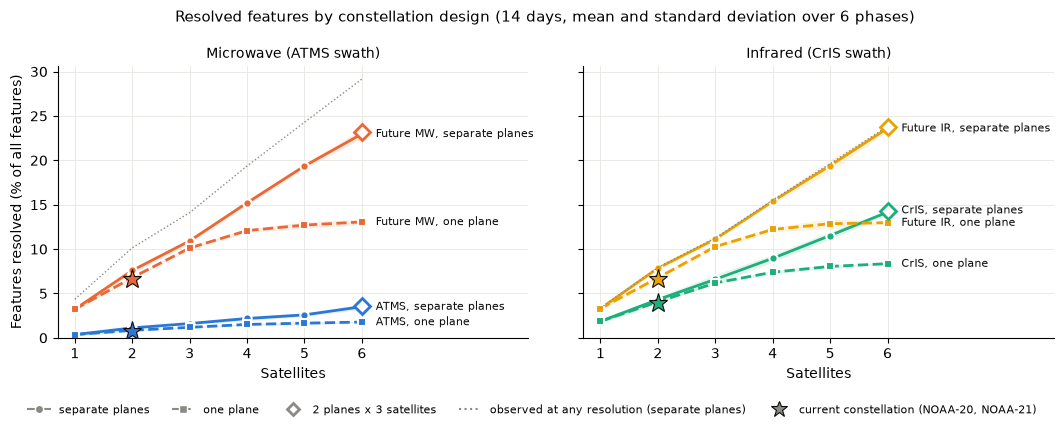

In [15]:
STRATEGIES = {"separate planes": ("-", "o"), "one plane": ("--", "s")}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (title, pair) in zip(
    axes,
    {
        "Microwave (ATMS swath)": ("ATMS", "Future MW"),
        "Infrared (CrIS swath)": ("CrIS", "Future IR"),
    }.items(),
):
    ends = []
    for sensor in pair:
        color = SENSOR_COLORS[sensor]
        for strategy, (ls, marker) in STRATEGIES.items():
            selected = trade[
                (trade.sensor == sensor)
                & (
                    (trade.planes == 1)
                    if strategy == "one plane"
                    else (trade.per_plane == 1)
                )
            ]
            stats = selected.groupby("satellites")["resolved"].agg(["mean", "std"])
            ax.fill_between(
                stats.index,
                stats["mean"] - stats["std"],
                stats["mean"] + stats["std"],
                color=color,
                alpha=0.12,
                lw=0,
            )
            ax.plot(
                stats.index,
                stats["mean"],
                ls=ls,
                marker=marker,
                ms=6,
                lw=2,
                color=color,
                mec="white",
                mew=1.5,
            )
            ends.append([stats["mean"].iloc[-1], f"{sensor}, {strategy}"])
        two_planes = trade[
            (trade.sensor == sensor) & (trade.planes == 2) & (trade.per_plane == 3)
        ]["resolved"].mean()
        ax.plot(
            6, two_planes, marker="D", ms=8, color="white", mec=color, mew=2, zorder=3
        )
        # the current constellation
        ax.plot(
            len(satellites),
            current.loc[sensor, "resolved"],
            marker="*",
            ms=14,
            color=color,
            mec=INK,
            mew=0.8,
            zorder=4,
        )
    # direct labels at the line ends, nudged apart so that they do not overlap
    ends.sort()
    for i in range(1, len(ends)):
        ends[i][0] = max(ends[i][0], ends[i - 1][0] + 1.4)
    for y, label in ends:
        ax.annotate(
            label,
            (6, y),
            xytext=(10, 0),
            textcoords="offset points",
            va="center",
            fontsize=8,
            color=INK,
        )
    # the features observed at any resolution, with separate planes: the most that any sensor can resolve
    observed = (
        trade[(trade.sensor == pair[0]) & (trade.per_plane == 1)]
        .groupby("satellites")["observed"]
        .mean()
    )
    ax.plot(observed.index, observed, color=GRAY, lw=1, ls=":")
    ax.set(title=title, xlabel="Satellites", xticks=range(1, 7), xlim=(0.7, 8.9))
    ax.title.set_fontsize(10)
axes[0].set(ylabel="Features resolved (% of all features)", ylim=(0, None))
legend = [
    plt.Line2D(
        [], [], color=GRAY, ls="-", marker="o", mec="white", label="separate planes"
    ),
    plt.Line2D([], [], color=GRAY, ls="--", marker="s", mec="white", label="one plane"),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="D",
        mfc="white",
        mew=2,
        label="2 planes x 3 satellites",
    ),
    plt.Line2D(
        [], [], color=GRAY, ls=":", label="observed at any resolution (separate planes)"
    ),
    plt.Line2D(
        [],
        [],
        color=GRAY,
        ls="none",
        marker="*",
        ms=12,
        mec=INK,
        mew=0.8,
        label=f"current constellation ({', '.join(tles)})",
    ),
]
fig.legend(handles=legend, loc="lower center", ncol=5, fontsize=8, frameon=False)
fig.suptitle(
    f"Resolved features by constellation design ({TRADE_DURATION.days} days, mean and standard deviation over {N_DRAWS} phases)",
    fontsize=11,
)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

Over the two weeks, the study region has 1,590 features. The current constellation observes 8% of them in the ATMS swath and 7% in the CrIS swath, and resolves 1% (ATMS), 4% (CrIS), and 7% (either future sensor), close to the two days above. Its two satellites are about half an orbit apart, so it does about as well as two satellites evenly spaced in its plane (8.5% and 6.8% observed): the stars in the figure, on the lines of one plane.

* **Satellites in one plane saturate.** Adding satellites to a single plane observes more features up to about four satellites, and then hardly any more (15 to 16% in the ATMS swath for four to six satellites), because they all observe at the same local times (near 13:30 and 01:30).
* **A second plane gives most of the benefit.** Six satellites in separate planes observe 29% of the features, almost twice as many as six in one plane. Six satellites in two planes (three in each) observe as many (30%), and in three planes (two in each) nearly as many (28%); likewise, four satellites in two planes observe as many as four in separate planes (19 to 20%). What matters is that the satellites do not duplicate each other's local times, not how many planes there are.
* **Planes and resolution trade against each other.** With heritage sensors, six satellites in separate planes resolve 14.2% of the features with CrIS, more than six satellites with a future infrared sounder in one plane (13.0%). Finer resolution pays off fully only with separate planes: a future sounder on six satellites in separate (or two or three) planes resolves 22 to 24% of the features: nearly all of those observed in the CrIS swath, and four fifths of those in the wider ATMS swath.
* **ATMS is limited by resolution, not sampling.** More planes raise the share resolved by ATMS only from 2% to 4%, because its resolution element is larger than most features wherever they are observed.

The spread between the random phases (the shaded bands) is small compared with these differences. The trade holds the sensors and the altitude fixed; their swaths, altitudes, and resolutions, and orbits other than sun-synchronous ones, are further dimensions of a full trade study, which would add variables to the design space.

### Pareto-efficient designs

A design is Pareto-efficient if no other design is as good in every objective and better in one. With three objectives (the fewest satellites, the fewest orbit planes, each of which needs its own launch, and the most features resolved), the table gives the share of features resolved by each sensor's efficient designs (`tatc.tradespace.pareto_front`, from the means over the replicates by `tatc.tradespace.summarize`), blank where a design is not efficient for a sensor.

In [16]:
from tatc.tradespace import pareto_front, summarize

OBJECTIVES = {"satellites": "min", "planes": "min", "resolved": "max"}
# the mean shares over the replicates, by design and sensor, and the efficient designs of each sensor
trade_means = summarize(trade, statistics=["observed", "resolved"], by=["sensor"])
efficient = pd.concat(
    [group[pareto_front(group, OBJECTIVES)] for _, group in trade_means.groupby("sensor")]
)
efficient.pivot_table(
    index=["satellites", "planes", "per_plane"], columns="sensor", values="resolved"
)[sensors.index].round(1)

sensor                       ATMS  CrIS  Future MW  Future IR
satellites planes per_plane                                  
1          1      1           0.4   1.9        3.2        3.3
2          1      2           0.8   4.1        6.8        6.8
           2      1           1.1   4.3        7.6        7.9
3          1      3           1.2   6.2       10.1       10.3
           3      1           1.6   6.6       10.9       11.1
4          1      4           1.5   7.4       12.1       12.2
           2      2           2.4   9.2       15.4       15.6
5          1      5           1.7   8.1       12.7       12.9
           5      1           2.6  11.5       19.4       19.4
6          1      6           1.8   8.4       13.1       13.0
           2      3           3.6  14.2       23.2       23.7

For every sensor, the efficient designs are those in one plane (the fewest launches) and those in two planes (the most features resolved for the number of satellites): two planes of two satellites resolve more features than four planes of one, and two planes of three about as many as six planes of one, with fewer launches. Designs with more than two planes are efficient only if their satellites cannot be divided evenly between two planes (three or five satellites, in separate planes). Some of these differences are smaller than the spread between the replicates (the standard errors of the means are given by `summarize`), so designs that are nearly efficient deserve as much attention as those that are.

## Limitations

* **Resolution is geometric.** A sounder's resolution depends on its channels, the retrieval, and the scene. The resolution element here is the larger of the nominal footprint and the sample spacing, scaled by the viewing geometry, without modeling the response (point spread function) of each footprint, the overlap of neighbouring footprints, or where the gaps between the views of CrIS fall on a feature. Taking the larger of the footprint and the spacing is optimistic where the two are similar, as for CrIS and a future infrared sounder; the `"quadrature"` element bounds it (see the sensitivity above).
* **Infrared sounders do not see through cloud.** Cold cloud tops, the features here, are observed by CrIS at their tops but, unlike microwave sounders, it does not observe the atmosphere beneath. This is not modeled.
* **The future sensors are assumed.** They share the swaths and platforms of ATMS and CrIS and a nominal resolution, and sample in proportion to their footprints, which requires many more views per scan (about 20 times as many for a future infrared sounder as for CrIS). Their own swaths and altitudes are open design variables; the constellation trade varies only the number of satellites and their orbit planes, at the altitude at which the nominal resolutions apply.
* **One realization.** Two days of one nature run year are a small sample (the constellation trade uses two weeks, over which the shares of features that the current constellation resolves differ from those of the two days by up to 1 percentage point). Extend `duration` and `start` to the whole season (mid-June to mid-September) and other years of the Nature Run for statistics.
* **The minimum feature size is a choice.** Features smaller than the Nature Run's effective resolution (`EFFECTIVE_RESOLUTION_KM`, four grid spacings by default) are excluded, about half of the patches of two or more grid cells. The G5NR evaluation gives no single value, and a smaller one would admit features whose structure is set by the model's damping of small scales rather than its physics.
* **Features are snapshots.** A convective system that persists is a feature in each 30-minute frame, and the features of a frame are not tracked from frame to frame.
* **The Nature Run is not reality.** Its convection is simulated and its feature statistics differ from those observed, so the results show the effect of the observing systems on a nature run, which is the point of an OSSE, rather than a forecast of real observations.